# Chen et al. 2021 — Prostate Cancer (10x)
## 04 · EMT-TF expression (unconditional final step)

The EMT-TF step runs regardless of gate outcome; numbered **04** here (non-branching: 01–03 + expression). Panel widened beyond Snail/Zeb/Twist to include FOXC and PRRX families (per the evaluation lesson), scored on this dataset and gated on detectable expression. Each TF is labelled by its **actual** direction along pseudotime (sign of Spearman ρ), not assumed to split into an early vs a late factor. Categorical overlay of thresholded expressers on a grey manifold — the house plotting style.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load signatures h5ad, adopt the linear layout

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 14266 | pseudotime range 0.0 -> 8.84


### Score the EMT-TF panel — detection frac + direction along pseudotime
`direction` is read from the sign of ρ(TF, pseudotime): ρ<0 = root-enriched (declines toward the terminus), ρ>0 = terminus-enriched. The two most informative **expressed** TFs (|ρ|, frac_expr>0.03) are the panel — with no assumption that one marks the root and one the terminus.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['direction'] = np.where(df.rho_vs_t < 0, 'root-enriched', 'terminus-enriched')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
sel = ok.reindex(ok.rho_vs_t.abs().sort_values(ascending=False).index).head(2)
tf1, tf2 = sel.iloc[0]['TF'], sel.iloc[1]['TF']
d1, d2 = sel.iloc[0]['direction'], sel.iloc[1]['direction']
r1, r2 = sel.iloc[0]['rho_vs_t'], sel.iloc[1]['rho_vs_t']
print(f'\ninformative expressed EMT-TFs: {tf1} ({d1}, rho={r1:+.3f}), {tf2} ({d2}, rho={r2:+.3f})')
n_term = int((ok.rho_vs_t > 0).sum())
print(f'terminus-enriched EMT-TFs among expressed: {n_term}',
      '-> no EMT-TF marks the neural-crest terminus; both leading factors decline toward it (FOXC1 most steeply).'
      if n_term==0 else '')

    TF  frac_expr  mean_early  mean_late  rho_vs_t         direction
 FOXC1      0.066       0.034      0.015    -0.094     root-enriched
TWIST1      0.076       0.040      0.021    -0.064     root-enriched
 SNAI2      0.006       0.004      0.001    -0.042     root-enriched
 SNAI1      0.030       0.011      0.007    -0.024     root-enriched
  ZEB2      0.006       0.003      0.001    -0.022     root-enriched
  ZEB1      0.004       0.002      0.001    -0.015     root-enriched
 PRRX2      0.001       0.000      0.000    -0.012     root-enriched
TWIST2      0.000       0.000      0.000    -0.003     root-enriched
 PRRX1      0.001       0.001      0.000    -0.002     root-enriched
 FOXC2      0.000       0.000      0.000     0.002 terminus-enriched

informative expressed EMT-TFs: FOXC1 (root-enriched, rho=-0.094), TWIST1 (root-enriched, rho=-0.064)
terminus-enriched EMT-TFs among expressed: 0 -> no EMT-TF marks the neural-crest terminus; both leading factors decline toward it (FOXC1 mo

### `expression.pdf` — categorical overlay of thresholded expressers

overlay thresholds (upper quartile among expressers): {'FOXC1': 0.458, 'TWIST1': 0.493} | cells shown: {'FOXC1': 237, 'TWIST1': 270}
FOXC1: 6.6% expressing; 237 shown, mean pseudotime of shown = 0.39 (all cells = 0.50)
TWIST1: 7.6% expressing; 270 shown, mean pseudotime of shown = 0.38 (all cells = 0.50)
saved expression.pdf


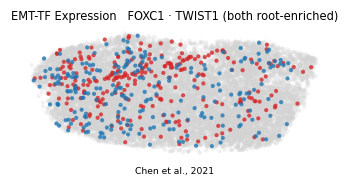

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [tf1, tf2]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
selm = {g: _vec(g) > thr[g] for g in [tf1, tf2]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [tf1, tf2]},
      '| cells shown:', {g: int(selm[g].sum()) for g in [tf1, tf2]})
order = sorted([tf1, tf2], key=lambda g: -int(selm[g].sum()))
colors = {tf1:'tab:blue', tf2:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[selm[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {tf1} · {tf2} (both root-enriched)', size=7.5)
ax.text(.5,-.14,'Chen et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [tf1, tf2]:
    m = selm[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown, '
          f'mean pseudotime of shown = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
print('saved expression.pdf')